# 09. Transaction – Frequency & Monetary theo Label

## Câu hỏi

### Frequency

- Số basket trên active day có liên quan label không?
- Basket count quá khứ có quan hệ label không?

### Monetary

- Khách chi nhiều có propensity cao hơn không?
- Giá trị trung bình mỗi basket có liên quan khả năng quay lại không?
- Shopping-value điển hình có khác label không?
- Một basket rất lớn có liên quan short-term return không?
- Spending intensity trên active day có signal không?

Mọi feature chỉ dùng giao dịch trong `[cutoff-90, cutoff-1]`.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from propensity.eda.transaction_frequency_monetary_label import (
    load_transaction_frequency_monetary_report,
)
from propensity.eda.transaction_frequency_monetary_plots import (
    plot_frequency_monetary_boxplots,
)


## 1. Build leakage-safe frequency và monetary features

In [2]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

label_path = project_root / "data" / "processed" / "purchase_propensity_t90_h7_step7" / "household_cutoff_labels.parquet"
transaction_path = project_root / "data" / "raw" / "Dunnhumby" / "transaction_data.csv"

report = load_transaction_frequency_monetary_report(
    label_path,
    transaction_path,
    observation_days=90,
)


## 2. Định nghĩa feature

| Feature | Định nghĩa trong 90 ngày trước cutoff |
|---|---|
| `baskets_per_active_day_90d` | Số basket / số active days |
| `n_baskets_90d` | Tổng basket count |
| `total_sales_value_90d` | Tổng `SALES_VALUE` của các basket hợp lệ |
| `avg_spend_per_basket_90d` | Tổng spend / số basket |
| `median_basket_value_90d` | Median basket-level `SALES_VALUE` |
| `max_basket_value_90d` | Basket value lớn nhất |
| `spend_per_active_day_90d` | Tổng spend / số active days |

In [3]:
report.summary_by_label

,feature,label,n_observations,missing_rate,p10,q1,median,q3,p90
0,baskets_per_active_day_90d,0,80878,0.147045,1.00000,1.000000,1.000000,1.153846,1.333333
1,baskets_per_active_day_90d,1,106384,0.009672,1.00000,1.000000,1.115385,1.250000,1.407407
2,n_baskets_90d,0,94821,0.000000,0.00000,2.000000,5.000000,10.000000,16.000000
3,n_baskets_90d,1,107423,0.000000,5.00000,9.000000,17.000000,28.000000,45.000000
4,total_sales_value_90d,0,94821,0.000000,0.00000,24.600000,110.000000,287.000000,556.010000
5,total_sales_value_90d,1,107423,0.000000,90.45200,223.585000,478.100000,883.605000,1409.364000
6,avg_spend_per_basket_90d,0,80878,0.147045,8.11450,14.010769,24.819355,41.314286,64.670000
7,avg_spend_per_basket_90d,1,106384,0.009672,10.84965,17.285461,27.278333,41.488006,59.270955
8,median_basket_value_90d,0,80878,0.147045,6.19000,10.550000,19.160000,33.540000,58.344500
9,median_basket_value_90d,1,106384,0.009672,7.16000,11.930000,20.000000,31.770000,48.590000


## 3. Box plot theo label

Whisker dùng quy tắc 1,5 × IQR. Outlier được hiển thị bằng marker nhỏ với alpha thấp để hạn chế chồng lấn. Mỗi subplot dùng thang đo tự nhiên riêng.

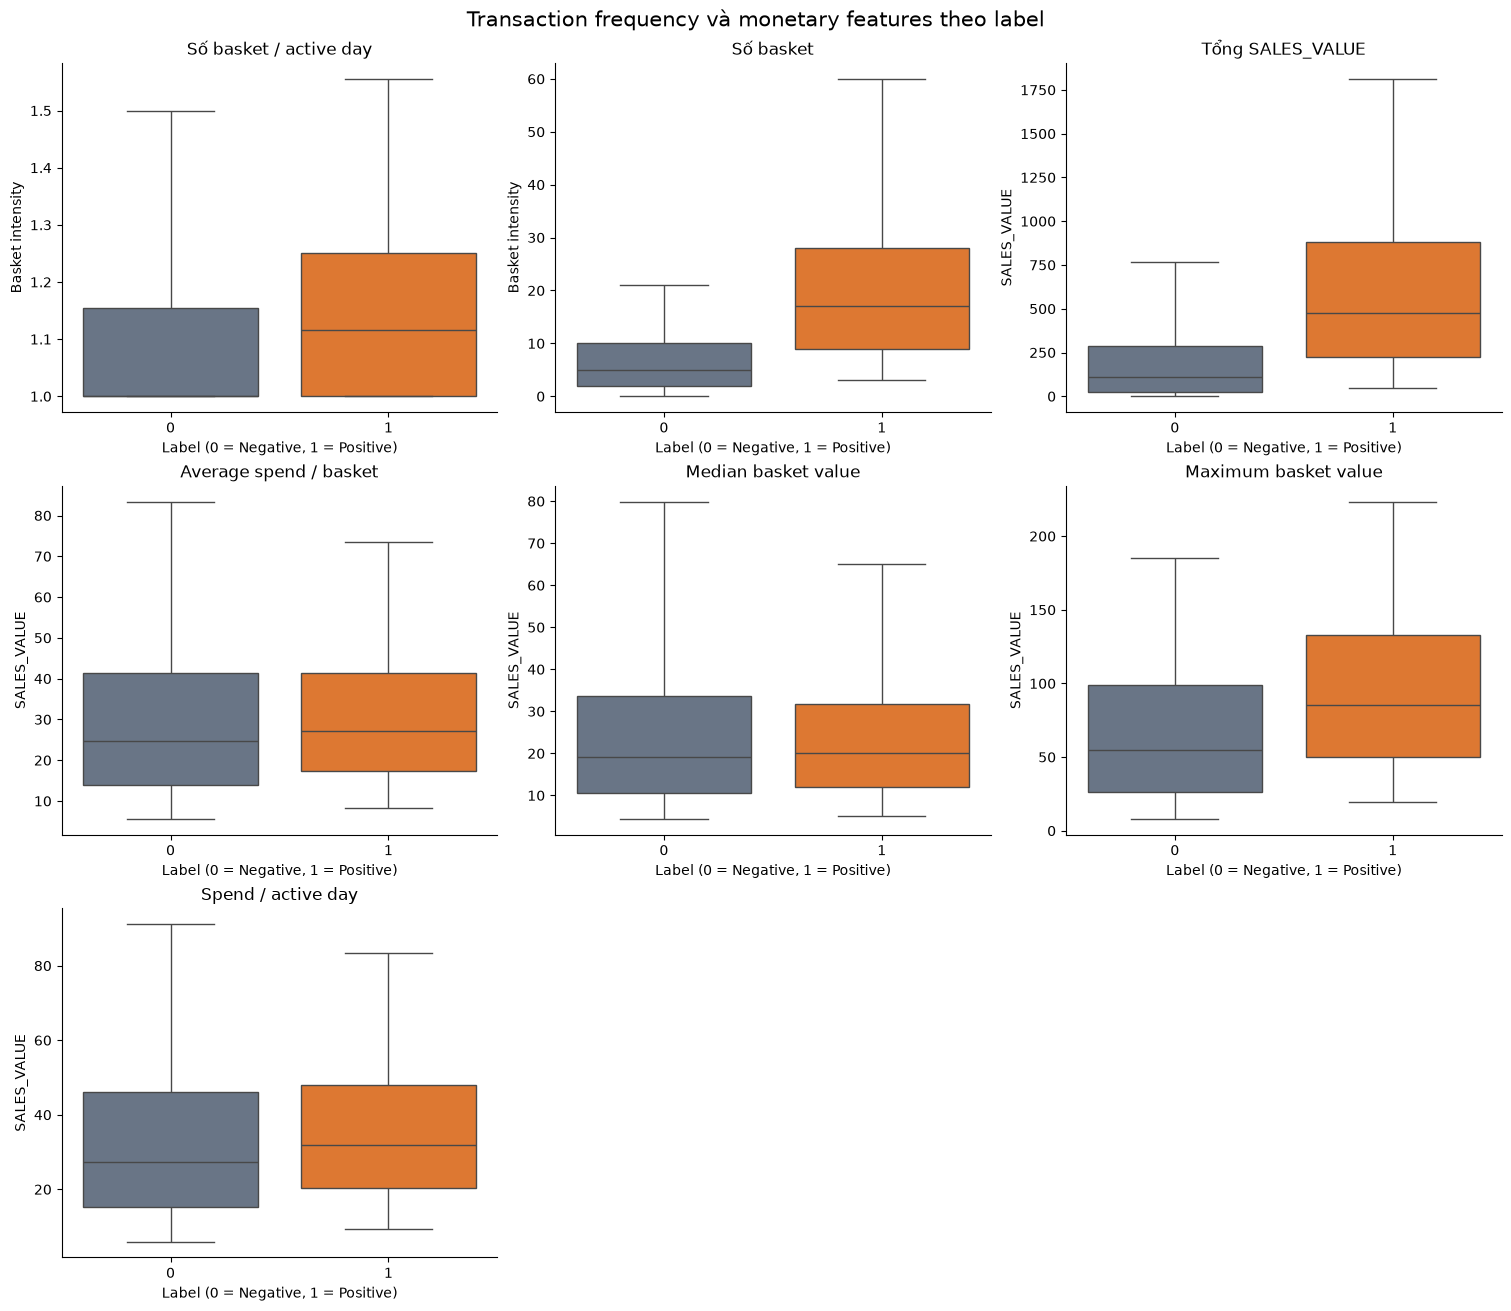

In [4]:
figure = plot_frequency_monetary_boxplots(report.feature_panel)
plt.show()

## Lưu ý diễn giải

- Basket value được tính sau khi cộng `SALES_VALUE` của các product lines hợp lệ trong cùng basket.
- Giao dịch ngày cutoff không được dùng làm feature.
- Household không có activity trong window có basket count và total sales bằng 0; các ratio/basket statistics là null vì không xác định.
- Monetary features thường lệch phải; cần đọc median và P5–P95 thay vì chỉ nhìn mean.
- Box plot thể hiện association, không chứng minh frequency hoặc spending gây ra label dương.
- Parquet label cần được tạo lại sau khi target window đổi thành `[cutoff, cutoff+6]`.